<a href="https://colab.research.google.com/github/giuliavalcu/ML-Seminar-ValcuGiulia/blob/main/Tema_Laborator_2_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Exercițiu LP2 — Setul de date Penguins

**de lucru individual — aprox. 30 minute**

Ați exersat în LP2 explorarea structurii datelor, curățarea lor, statisticile descriptive și principalele tipuri de grafice, pe setul de date Galton. În acest exercițiu aplicați aceleași tehnici pe un set de date nou: **Palmer Penguins** — măsurători pentru 344 de pinguini din trei specii, colectate în Arhipelagul Palmer, Antarctica.

**Variabile:**
- `species` — specia pinguinului: Adelie, Chinstrap sau Gentoo
- `island` — insula pe care a fost observat: Biscoe, Dream sau Torgersen
- `bill_length_mm`, `bill_depth_mm` — lungimea și adâncimea ciocului (mm)
- `flipper_length_mm` — lungimea aripioarei (mm)
- `body_mass_g` — masa corporală (g)
- `sex` — sexul pinguinului

### Instrucțiuni
- Lucrați **individual**, timp de aproximativ 30 de minute.
- Completați celulele marcate cu `# TODO`, folosind comenzile exersate în LP2.
- Nu este nevoie să scrieți cod perfect — scopul e să exersați, nu să obțineți un rezultat impecabil.
- Dacă rămâneți blocați mai mult de 4-5 minute la o cerință, treceți la următoarea și reveniți la final.

### Pregătire — rulați celula de mai jos (nu necesită modificări)

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

penguins_df = sns.load_dataset('penguins')
penguins_df.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


## Sarcina 1 — Explorarea structurii datelor (~5 min)

**1.1** Afișați dimensiunea setului de date (număr de rânduri și coloane).

In [ ]:
penguins_df.shape


(344, 7)

**1.2** Afișați tipul de date al fiecărei coloane.

In [ ]:
penguins_df.dtypes

,0
species,object
island,object
bill_length_mm,float64
bill_depth_mm,float64
flipper_length_mm,float64
body_mass_g,float64
sex,object


**1.3** Afișați un rezumat descriptiv pentru **toate** variabilele (numerice și categoriale).

In [ ]:
penguins_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
dtypes: float64(4), object(3)
memory usage: 18.9+ KB


**1.4** Câte specii distincte de pinguini există în setul de date? Care sunt ele? *(indiciu: `nunique()` și `unique()`)*

In [ ]:
print(f"Numar de specii distincte: {penguins_df['species'].nunique()}")
print(f"Speciile sunt: {penguins_df['species'].unique()}")

Numar de specii distincte: 3
Speciile sunt: ['Adelie' 'Chinstrap' 'Gentoo']


## Sarcina 2 — Manipularea datelor (~5 min)

**2.1** Selectați și afișați doar coloanele `species`, `island` și `body_mass_g`.

In [ ]:
selected_columns = penguins_df[['species', 'island', 'body_mass_g']]
display(selected_columns.head())

,species,island,body_mass_g
0,Adelie,Torgersen,3750.0
1,Adelie,Torgersen,3800.0
2,Adelie,Torgersen,3250.0
3,Adelie,Torgersen,NaN
4,Adelie,Torgersen,3450.0


**2.2** Filtrați setul de date pentru a păstra doar pinguinii din specia `Gentoo`. Salvați rezultatul într-o variabilă nouă, `gentoo_df`.

In [ ]:
gentoo_df = penguins_df[penguins_df['species'] == 'Gentoo']
display(gentoo_df.head())

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
220,Gentoo,Biscoe,46.1,13.2,211.0,4500.0,Female
221,Gentoo,Biscoe,50.0,16.3,230.0,5700.0,Male
222,Gentoo,Biscoe,48.7,14.1,210.0,4450.0,Female
223,Gentoo,Biscoe,50.0,15.2,218.0,5700.0,Male
224,Gentoo,Biscoe,47.6,14.5,215.0,5400.0,Male


**2.3** Selectați un eșantion aleator de 10 rânduri din setul de date original.

In [ ]:
random_sample = penguins_df.sample(10)
display(random_sample)

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
12,Adelie,Torgersen,41.1,17.6,182.0,3200.0,Female
168,Chinstrap,Dream,50.3,20.0,197.0,3300.0,Male
302,Gentoo,Biscoe,47.4,14.6,212.0,4725.0,Female
162,Chinstrap,Dream,46.6,17.8,193.0,3800.0,Female
270,Gentoo,Biscoe,46.6,14.2,210.0,4850.0,Female
155,Chinstrap,Dream,45.4,18.7,188.0,3525.0,Female
303,Gentoo,Biscoe,50.0,15.9,224.0,5350.0,Male
27,Adelie,Biscoe,40.5,17.9,187.0,3200.0,Female
21,Adelie,Biscoe,37.7,18.7,180.0,3600.0,Male
28,Adelie,Biscoe,37.9,18.6,172.0,3150.0,Female


## Sarcina 3 — Curățarea datelor (~5 min)

**3.1** Câte valori lipsă (`NaN`) are fiecare coloană?

In [ ]:
missing_values = penguins_df.isna().sum()
print(missing_values)

species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64


**3.2** Eliminați rândurile cu valori lipsă și salvați rezultatul într-un nou DataFrame, `penguins_clean`.

In [ ]:
penguins_clean = penguins_df.dropna()
display(penguins_clean.head())

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,Male


**3.3** Verificați dimensiunea noului set de date. Câte rânduri au fost eliminate față de setul inițial?

In [ ]:
initial_rows = penguins_df.shape[0]
clean_rows = penguins_clean.shape[0]
eliminated_rows = initial_rows - clean_rows

print(f"Dimensiunea setului curățat: {penguins_clean.shape}")
print(f"Număr de rânduri eliminate: {eliminated_rows}")

Dimensiunea setului curățat: (333, 7)
Număr de rânduri eliminate: 11


## Sarcina 4 — Statistici descriptive (~7 min)

*Folosiți `penguins_clean` pentru sarcinile de mai jos.*

**4.1** Calculați masa corporală medie (`body_mass_g`), pentru fiecare specie.

In [ ]:
average_mass_by_species = penguins_clean.groupby('species')['body_mass_g'].mean()
print(average_mass_by_species)

species
Adelie       3706.164384
Chinstrap    3733.088235
Gentoo       5092.436975
Name: body_mass_g, dtype: float64


**4.2** Care specie are, în medie, cea mai lungă aripioară (`flipper_length_mm`)?

In [ ]:
avg_flipper_by_species = penguins_clean.groupby('species')['flipper_length_mm'].mean()
print(avg_flipper_by_species)
print(f"\nSpecia cu cea mai lungă aripioară în medie este: {avg_flipper_by_species.idxmax()}")

species
Adelie       190.102740
Chinstrap    195.823529
Gentoo       217.235294
Name: flipper_length_mm, dtype: float64

Specia cu cea mai lungă aripioară în medie este: Gentoo


**4.3** Afișați frecvența (numărul de observații) pentru fiecare insulă (`island`).

In [ ]:
island_counts = penguins_clean['island'].value_counts()
print(island_counts)

island
Biscoe       163
Dream        123
Torgersen     47
Name: count, dtype: int64


**4.4** Ce procent din pinguini sunt masculi și ce procent sunt femele, în setul curățat? *(indiciu: `value_counts(normalize=True)`)*

In [ ]:
gender_proportions = penguins_clean['sex'].value_counts(normalize=True) * 100
print(gender_proportions)

sex
Male      50.45045
Female    49.54955
Name: proportion, dtype: float64


## Sarcina 5 — Vizualizare (~8 min)

*Folosiți `penguins_clean` pentru graficele de mai jos.*

**5.1** Realizați un `countplot` pentru distribuția speciilor (`species`).

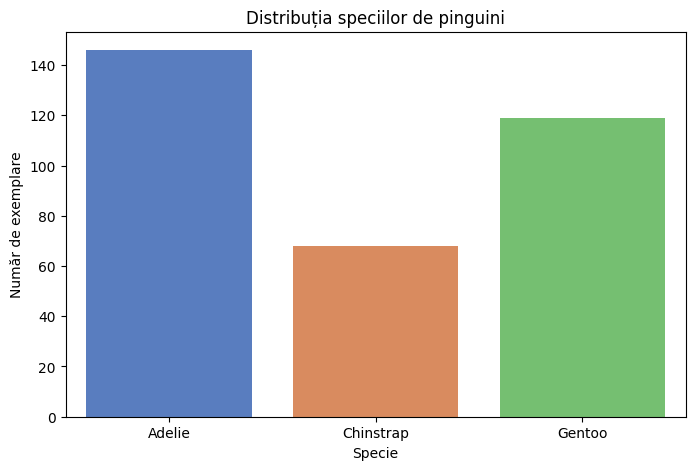

In [ ]:
plt.figure(figsize=(8, 5))
sns.countplot(data=penguins_clean, x='species', palette='muted')
plt.title('Distribuția speciilor de pinguini')
plt.xlabel('Specie')
plt.ylabel('Număr de exemplare')
plt.show()

**5.2** Realizați un `barplot` cu masa corporală medie pe specie, colorat (`hue`) în funcție de sex.

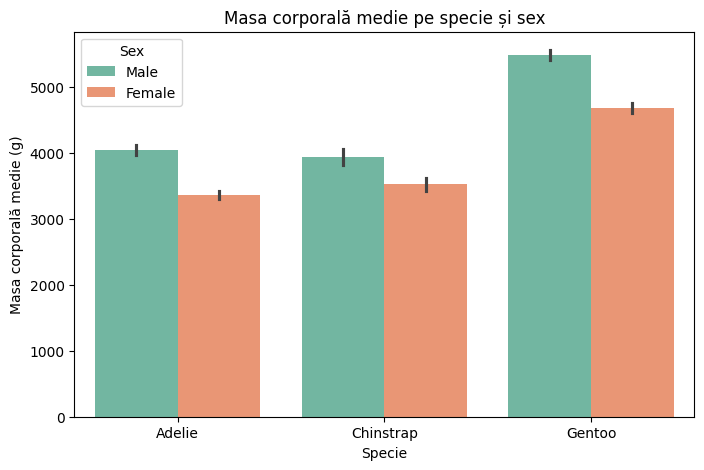

In [ ]:
plt.figure(figsize=(8, 5))
sns.barplot(data=penguins_clean, x='species', y='body_mass_g', hue='sex', palette='Set2')
plt.title('Masa corporala medie pe specie si sex')
plt.xlabel('Specie')
plt.ylabel('Masa corporala medie (g)')
plt.legend(title='Sex')
plt.show()

**5.3** Realizați un grafic de tip `relplot` (scatter) între `bill_length_mm` și `bill_depth_mm`, colorat după `species`.

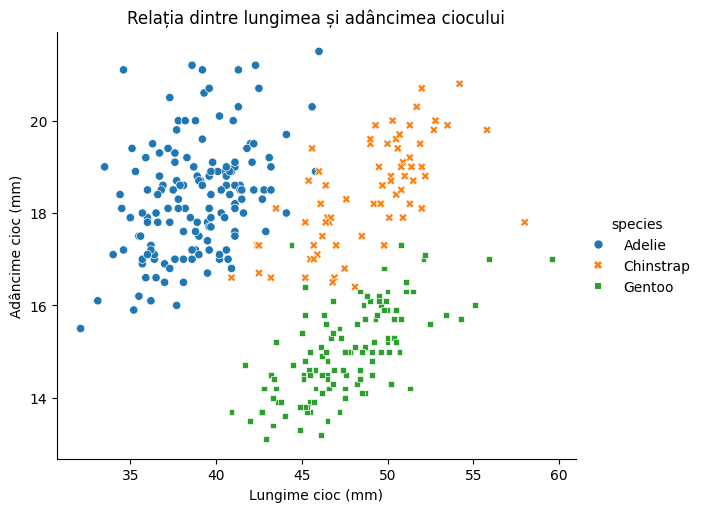

In [ ]:
sns.relplot(data=penguins_clean, x='bill_length_mm', y='bill_depth_mm', hue='species', style='species', height=5, aspect=1.2)
plt.title('Relația dintre lungimea și adâncimea ciocului')
plt.xlabel('Lungime cioc (mm)')
plt.ylabel('Adâncime cioc (mm)')
plt.show()

**5.4** Realizați un `boxplot` sau un `violinplot` (folosind `catplot`) pentru `flipper_length_mm`, pe fiecare specie.

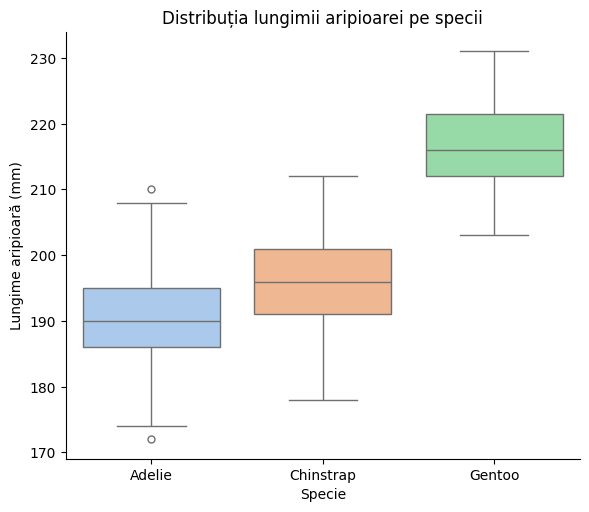

In [ ]:
sns.catplot(data=penguins_clean, x='species', y='flipper_length_mm', kind='box', palette='pastel', height=5, aspect=1.2)
plt.title('Distribuția lungimii aripioarei pe specii')
plt.xlabel('Specie')
plt.ylabel('Lungime aripioară (mm)')
plt.show()

**5.5** Realizați un `heatmap` cu matricea de corelații a variabilelor numerice.

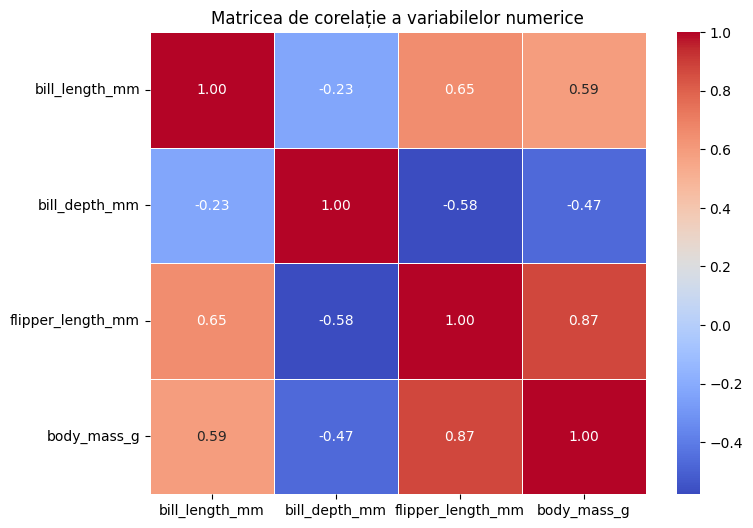

In [ ]:
# Selectăm doar coloanele numerice pentru calculul corelației
numeric_cols = penguins_clean.select_dtypes(include=[np.number])
correlation_matrix = numeric_cols.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Matricea de corelație a variabilelor numerice')
plt.show()

## Bonus (opțional, dacă ați terminat mai devreme)

- Există diferențe de masă corporală între insule (`island`)? Realizați un `barplot` sau un `boxplot` pentru a verifica.
- Realizați un `pairplot` cu `hue='species'` pentru întregul set curățat — ce observați?

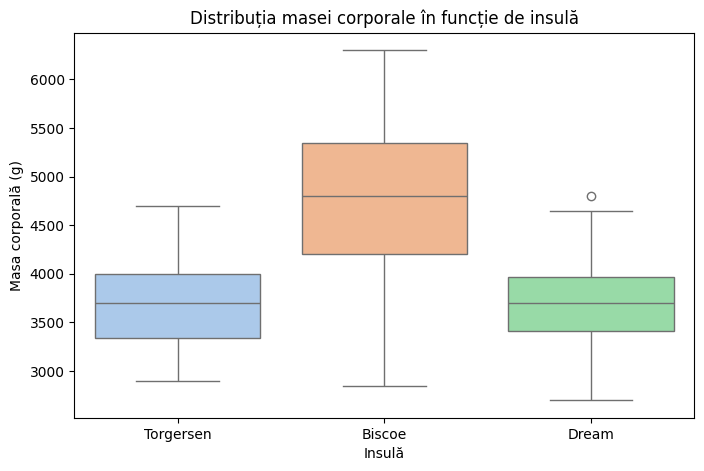

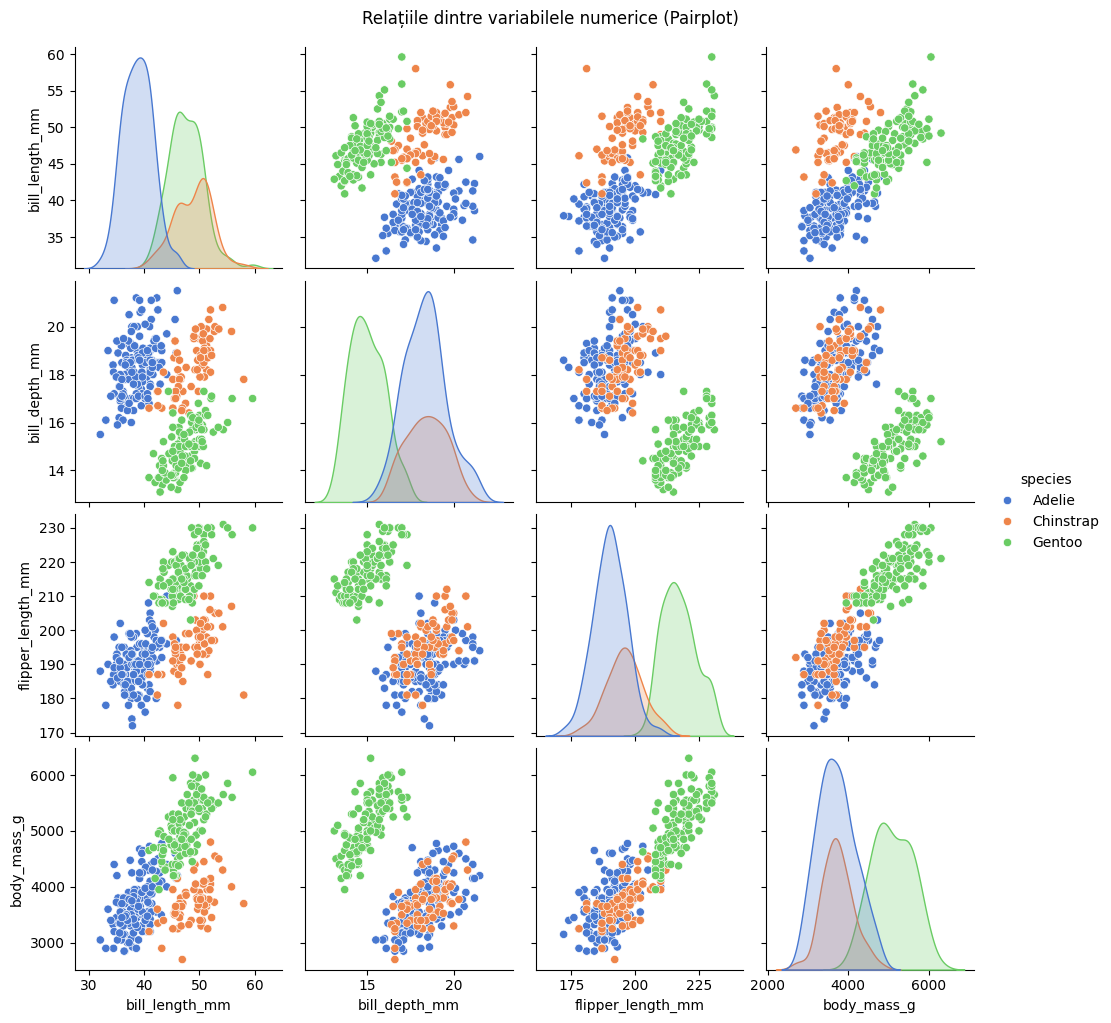

In [ ]:
# 1. Analiza diferențelor de masă corporală între insule
plt.figure(figsize=(8, 5))
sns.boxplot(data=penguins_clean, x='island', y='body_mass_g', palette='pastel')
plt.title('Distribuția masei corporale în funcție de insulă')
plt.xlabel('Insulă')
plt.ylabel('Masa corporală (g)')
plt.show()
#Diferențele de masă corporală între insule (island):
#Pinguinii de pe insula Biscoe sunt, în medie, semnificativ mai grei (masa corporală depășește adesea 4500g - 5000g)
#comparativ cu cei de pe insulele Torgersen și Dream, unde masa corporală se situează în general sub 4000g.
#Acest lucru este explicat prin faptul că majoritatea pinguinilor din specia masivă Gentoo trăiesc pe insula Biscoe.


# 2. Pairplot pentru întregul set de date curățat
sns.pairplot(data=penguins_clean, hue='species', palette='muted', height=2.5)
plt.suptitle('Relațiile dintre variabilele numerice (Pairplot)', y=1.02)
plt.show()
#Relațiile multivariate din pairplot:
#Separare clară: Graficul arată că speciile de pinguini se grupează foarte clar în funcție de combinațiile de caracteristici fizice.
#Identificare rapidă: Specia Gentoo (reprezentată cu verde) se diferențiază clar prin aripioare mai lungi (flipper_length_mm)
#și greutate mai mare (body_mass_g), dar cu o adâncime a ciocului mai mică.
#Specia Adelie (albastru) și specia Chinstrap (portocaliu) se suprapun parțial la greutate și lungimea aripioarei,
#însă pot fi separate foarte ușor prin lungimea ciocului (bill_length_mm), unde pinguinii Chinstrap au ciocul considerabil mai lung.